# HCAID Kredietrisico: data, model en ethiek

Dit notebook onderbouwt het model achter de twee apps:

- **Schuldwijzer** (goedaardig): waarschuwt vooraf als een lening waarschijnlijk niet te dragen is, legt uit waarom, en verwijst naar hulp.
- **SnelGeld** (kwaadaardig): gebruikt dezelfde soort voorspelling om juist kwetsbare mensen een dure lening te verkopen.

**Voorspelling:** de kans dat iemand een lening niet (goed) terugbetaalt, `class = bad`. Een classificatie met een neuraal netwerk (`MLPClassifier`) op minimaal 4 features en één outputvariabele.

Inhoud:
1. Data laden en verkennen
2. Is dit goede data? Kwaliteit en beperkingen
3. Ethisch risico in de data: bias
4. Feature-keuze voor beide apps
5. Training en evaluatie van het neurale netwerk
6. Precision of recall? De drempel van Schuldwijzer
7. Fairness-audit
8. Explainability: globaal en lokaal
9. Wat verlaagt het risico? (counterfactuals)
10. SnelGeld: dezelfde voorspelling, omgezet in winst
11. Conclusie

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from ml.config import (DATA_PATH, FEATURES, SCHULDWIJZER_FEATURES, SNELGELD_FEATURES,
                       SENSITIVE, DAMIAN, NUMERIC, RANDOM_STATE)
from ml.train import load_data, make_pipeline, mlp
from ml.explain import Predictor

sns.set_theme(style='whitegrid', context='notebook')
INK, ACC, RISK = '#0b1f33', '#00577a', '#c2410c'
pd.set_option('display.max_columns', 30)

## 1. Data laden en verkennen

**Dataset:** German Credit (Statlog), via OpenML `credit-g`. 1000 leningaanvragen bij een Duitse bank in de jaren '70, 20 kenmerken, en het label of de lening goed (`good`) of slecht (`bad`) is afgelopen.

We kozen deze dataset omdat de voorspelling (kredietrisico) direct ingrijpt in iemands leven. Daardoor zijn de ethische keuzes (privacy, bias, uitleg) concreet en voelbaar, en kun je met precies dezelfde voorspelling zowel beschermen als uitbuiten.

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [3]:
print('Ontbrekende waarden per kolom:', int(df.isna().sum().sum()))
df['class'].value_counts(normalize=True).rename('aandeel').to_frame()

Ontbrekende waarden per kolom: 0


,aandeel
class,
good,0.7
bad,0.3


70% van de leningen ging goed, 30% niet. De klassen zijn dus ongelijk verdeeld: een model dat altijd 'good' zegt, heeft al 70% accuracy. Daarom kijken we vooral naar **ROC AUC** en naar **recall op 'bad'**, niet naar accuracy alleen.

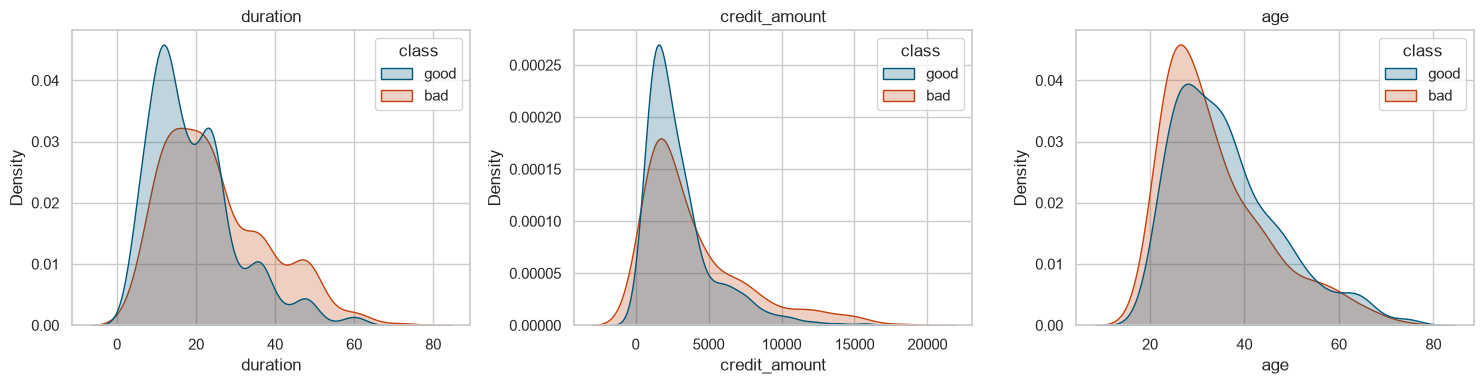

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['duration', 'credit_amount', 'age']):
    sns.kdeplot(data=df, x=col, hue='class', common_norm=False, fill=True, ax=ax,
                palette={'good': ACC, 'bad': RISK})
    ax.set_title(col)
plt.tight_layout(); plt.show()

Langere looptijden en hogere bedragen gaan vaker mis. Jongere aanvragers komen ook vaker in de problemen. Dat laatste is meteen een eerste ethisch signaal: leeftijd is een beschermd kenmerk.

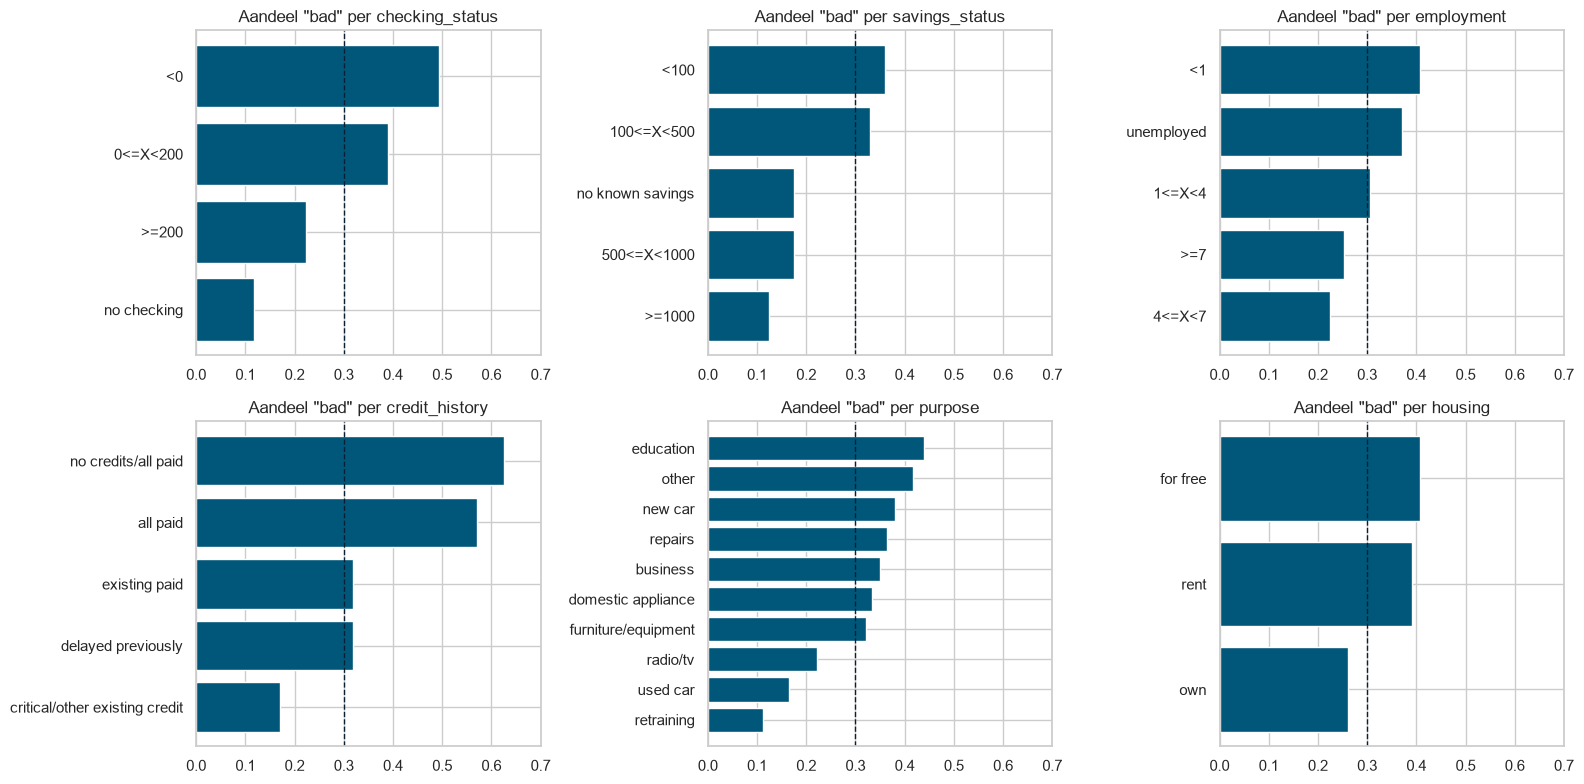

In [5]:
bad_rate = lambda s: (s == 'bad').mean()
cats = ['checking_status', 'savings_status', 'employment', 'credit_history', 'purpose', 'housing']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cats):
    r = df.groupby(col)['class'].apply(bad_rate).sort_values()
    ax.barh(r.index.astype(str), r.values, color=ACC)
    ax.axvline(0.3, color=INK, ls='--', lw=1)
    ax.set_title(f'Aandeel "bad" per {col}'); ax.set_xlim(0, 0.7)
plt.tight_layout(); plt.show()

## 2. Is dit goede data? Kwaliteit en beperkingen

Goede data laat **patronen** zien die logisch zijn en passen bij de vraag. Dat geldt hier grotendeels (saldo, spaargeld, looptijd, dienstverband), maar niet overal:

| Probleem | Wat we zien | Wat we ermee doen |
|---|---|---|
| **Oud en buitenlands** | Duitsland, jaren '70, bedragen in DM | Bedragen omgerekend (1 euro = 1,95583 DM); in de app benoemd als beperking |
| **Klein** | 1000 rijen, 300 'bad' | Simpel model, sterke regularisatie, cross-validation, eerlijke foutmarge in de app |
| **Kredietverleden werkt omgekeerd** | "critical/other existing credit" heeft het *laagste* risico (17%), "all paid" het hoogste (57%) | Waarschijnlijk selectiebias: wie een kritieke rekening had, kreeg alleen na strenge controle een lening. Weggelaten uit Schuldwijzer |
| **Geslacht en burgerlijke staat in één kolom** | `personal_status`, en "female" is niet uitgesplitst | Beschermd kenmerk, weggelaten uit Schuldwijzer |
| **`foreign_worker` scheef** | 96% "yes" | Te weinig data voor de andere groep; beschermd kenmerk, weggelaten |

In [6]:
df.groupby('credit_history')['class'].apply(bad_rate).sort_values().rename('aandeel bad').to_frame()

,aandeel bad
credit_history,
critical/other existing credit,0.170648
delayed previously,0.318182
existing paid,0.318868
all paid,0.571429
no credits/all paid,0.625000


## 3. Ethisch risico in de data: bias

Hoe vaak ging het mis per beschermde groep? Als die verschillen in de data zitten, leert een model ze over, tenzij we daar bewust iets aan doen.

In [7]:
grp = pd.DataFrame({
    'geslacht': df['personal_status'].map(lambda s: 'vrouw' if s.startswith('female') else 'man'),
    'leeftijd': pd.cut(df['age'], [0, 25, 200], labels=['25 of jonger', 'ouder dan 25']),
    'buitenlandse werknemer': df['foreign_worker'],
    'bad': (df['class'] == 'bad').astype(int),
})
rows = []
for g in ['geslacht', 'leeftijd', 'buitenlandse werknemer']:
    t = grp.groupby(g, observed=True)['bad'].agg(['count', 'mean']).reset_index()
    t.columns = ['groep', 'n', 'aandeel bad']; t.insert(0, 'kenmerk', g); rows.append(t)
pd.concat(rows).round(3)

,kenmerk,groep,n,aandeel bad
0,geslacht,man,690,0.277
1,geslacht,vrouw,310,0.352
0,leeftijd,25 of jonger,190,0.421
1,leeftijd,ouder dan 25,810,0.272
0,buitenlandse werknemer,no,37,0.108
1,buitenlandse werknemer,yes,963,0.307


Vrouwen (35% bad tegen 28%) en jongeren (42% tegen 27%) kwamen in deze data vaker in betalingsproblemen. Dat kan historische en maatschappelijke oorzaken hebben (lagere inkomens, kortere dienstverbanden), maar **een lening weigeren of duurder maken op basis van geslacht of leeftijd is discriminatie**.

- Schuldwijzer gebruikt deze kenmerken daarom niet.
- SnelGeld gebruikt ze juist wel, en rekent er zelfs een opslag voor.

## 4. Feature-keuze voor beide apps

**Schuldwijzer: dataminimalisatie.** Alleen vragen wat de voorspelling echt nodig heeft, en geen beschermde kenmerken. We vergelijken drie sets met 5-voudige cross-validation:

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

X, y = load_data()
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
sets = {
    'Alle 20 features (SnelGeld)': SNELGELD_FEATURES,
    'Zonder geslacht, leeftijd, nationaliteit': [f for f in SNELGELD_FEATURES if f not in SENSITIVE],
    'Schuldwijzer: 10 features, ook zonder kredietverleden': SCHULDWIJZER_FEATURES,
}
res = []
for name, feats in sets.items():
    for mname, m in [('Neuraal netwerk (8 neuronen)', mlp(hidden_layer_sizes=(8,), alpha=1.0)),
                     ('Logistische regressie', LogisticRegression(max_iter=2000, C=0.3))]:
        s = cross_val_score(make_pipeline(feats, m), X[feats], y, cv=cv, scoring='roc_auc')
        res.append({'featureset': name, 'model': mname, 'n features': len(feats),
                    'AUC (cv)': round(s.mean(), 3), 'std': round(s.std(), 3)})
pd.DataFrame(res)

,featureset,model,n features,AUC (cv),std
0,Alle 20 features (SnelGeld),Neuraal netwerk (8 neuronen),20,0.775,0.025
1,Alle 20 features (SnelGeld),Logistische regressie,20,0.789,0.019
2,"Zonder geslacht, leeftijd, nationaliteit",Neuraal netwerk (8 neuronen),17,0.786,0.029
3,"Zonder geslacht, leeftijd, nationaliteit",Logistische regressie,17,0.781,0.022
4,"Schuldwijzer: 10 features, ook zonder kredietv...",Neuraal netwerk (8 neuronen),10,0.776,0.026
5,"Schuldwijzer: 10 features, ook zonder kredietv...",Logistische regressie,10,0.770,0.023


**Conclusie:** met de helft van de vragen en zonder beschermde kenmerken presteert het model vrijwel even goed. De verschillen vallen binnen de standaardafwijking. Privacy en eerlijkheid kosten hier dus nauwelijks nauwkeurigheid: een sterk argument voor het ontwerp van Schuldwijzer.

**SnelGeld** vraagt alles, ook gegevens die het model niet nodig heeft (naam, e-mail, telefoon, contacten), omdat die commercieel waardevol zijn.

## 5. Training en evaluatie van het neurale netwerk

De training staat in `ml/train.py` (`python -m ml.train`). Per app:

1. 80/20 stratified split; de testset blijft ongezien.
2. `GridSearchCV` over architectuur (`(4,)`, `(8,)`, `(16,)`, `(8,4)`) en L2-regularisatie (`alpha`).
3. Sigmoid-kalibratie, zodat "72%" ook echt als kans te lezen is.
4. Evaluatie op de testset, naast twee baselines.
5. Het eindmodel voor de app wordt daarna op alle 1000 rijen getraind.

In [9]:
metrics = json.load(open(ROOT / 'models' / 'metrics.json'))
rows = []
for app, m in metrics.items():
    rows.append({'app': app, 'model': f"MLP {m['best_params']}", 'AUC cv': m['cv_auc'],
                 'AUC test': m['test']['roc_auc'], 'accuracy test (0,5)': m['test']['accuracy_05'],
                 'recall bad': m['test']['recall_bad'], 'precision bad': m['test']['precision_bad'],
                 'Brier': m['test']['brier']})
    for b, v in m['baselines'].items():
        rows.append({'app': app, 'model': f'baseline: {b}', 'AUC test': v['roc_auc'], 'accuracy test (0,5)': v['accuracy_05']})
pd.DataFrame(rows)

,app,model,AUC cv,AUC test,"accuracy test (0,5)",recall bad,precision bad,Brier
0,schuldwijzer,"MLP {'alpha': 1.0, 'hidden_layer_sizes': [8]}",0.778,0.783,0.755,0.683,0.519,0.168
1,schuldwijzer,baseline: altijd_good,NaN,0.500,0.700,NaN,NaN,NaN
2,schuldwijzer,baseline: logistische_regressie,NaN,0.786,0.765,NaN,NaN,NaN
3,snelgeld,"MLP {'alpha': 3.0, 'hidden_layer_sizes': [8]}",0.785,0.817,0.785,0.733,0.611,0.148
4,snelgeld,baseline: altijd_good,NaN,0.500,0.700,NaN,NaN,NaN
5,snelgeld,baseline: logistische_regressie,NaN,0.806,0.790,NaN,NaN,NaN


Het neurale netwerk is duidelijk beter dan de naïeve baseline (AUC 0,5, accuracy 70%) en vergelijkbaar met logistische regressie. Bij zo'n kleine dataset is dat te verwachten: de opdracht vraagt een neuraal netwerk, en we houden het bewust klein (8 neuronen, sterke regularisatie) om overfitting te voorkomen.

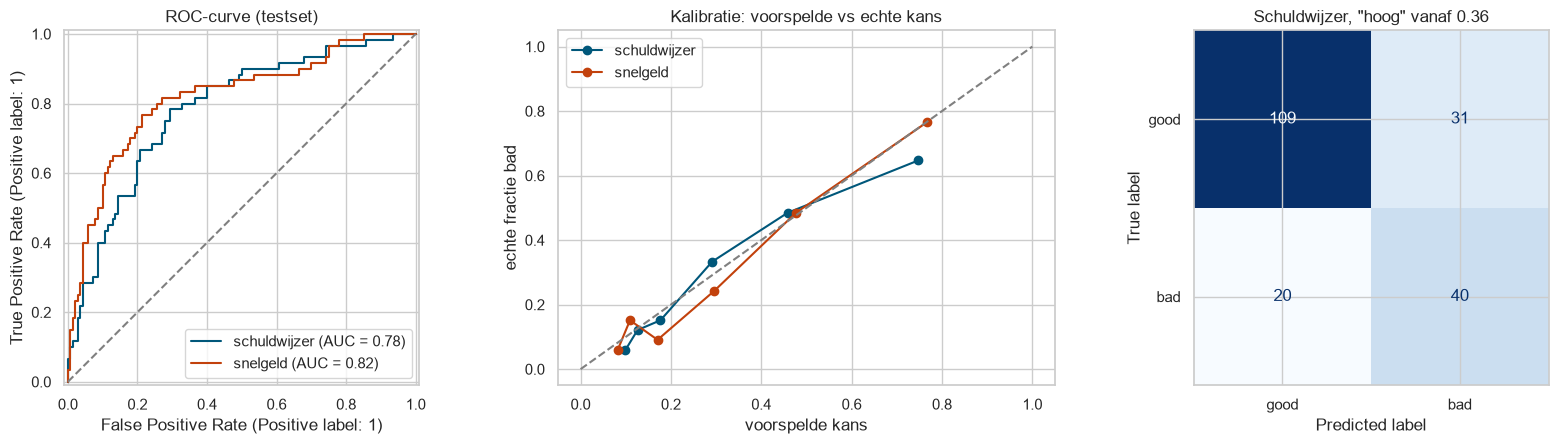

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for app, feats, color in [('schuldwijzer', SCHULDWIJZER_FEATURES, ACC), ('snelgeld', SNELGELD_FEATURES, RISK)]:
    bp = metrics[app]['best_params']
    bp = {k: tuple(v) if isinstance(v, list) else v for k, v in bp.items()}
    m = CalibratedClassifierCV(make_pipeline(feats, mlp(**bp)), method='sigmoid', cv=5, ensemble=False).fit(X_tr[feats], y_tr)
    p = m.predict_proba(X_te[feats])[:, 1]
    RocCurveDisplay.from_predictions(y_te, p, name=app, ax=axes[0], color=color)
    frac, mean = calibration_curve(y_te, p, n_bins=6, strategy='quantile')
    axes[1].plot(mean, frac, 'o-', color=color, label=app)
    if app == 'schuldwijzer':
        t = metrics[app]['thresholds']['hoog_vanaf']
        ConfusionMatrixDisplay.from_predictions(y_te, (p >= t).astype(int), display_labels=['good', 'bad'],
                                                ax=axes[2], cmap='Blues', colorbar=False)
        axes[2].set_title(f'Schuldwijzer, "hoog" vanaf {t:.2f}')
axes[0].plot([0, 1], [0, 1], ls='--', color='grey'); axes[0].set_title('ROC-curve (testset)')
axes[1].plot([0, 1], [0, 1], ls='--', color='grey'); axes[1].set_title('Kalibratie: voorspelde vs echte kans')
axes[1].set_xlabel('voorspelde kans'); axes[1].set_ylabel('echte fractie bad'); axes[1].legend()
plt.tight_layout(); plt.show()

## 6. Precision of recall? De drempel van Schuldwijzer

Wat is erger voor Damian?

- **Vals alarm (false positive):** Schuldwijzer waarschuwt, terwijl hij het had gered. Gevolg: hij praat met een schuldhulpverlener of leent iets minder. Vervelend, maar onschuldig.
- **Gemiste waarschuwing (false negative):** Schuldwijzer zegt "lijkt goed te dragen" en hij komt jaren in de schulden.

Schuldwijzer optimaliseert daarom op **recall** voor "bad". We delen de kans in drie groepen in, met grenzen die zijn bepaald op out-of-fold voorspellingen:

- "hoog" vangt 60% van alle probleemgevallen;
- "gemiddeld" of "hoog" samen vangen 90%.

Drie groepen zijn bovendien beter te begrijpen dan één kale kans (AI-UX: *confidence*).

In [11]:
pd.DataFrame(metrics['schuldwijzer']['bands'])

,band,van,tot,aandeel,werkelijk_bad
0,laag,0.000,0.135,0.324,0.093
1,gemiddeld,0.135,0.359,0.351,0.256
2,hoog,0.359,1.000,0.325,0.554


In de groep 'hoog' kreeg 55% echt betalingsproblemen, in 'laag' maar 9%. Precies die cijfers toont de app als zekerheid: eerlijk, inclusief het feit dat ook in 'hoog' bijna de helft het wél redde.

## 7. Fairness-audit

Hoe vaak komt elke groep in 'hoog' terecht (geflagd), en hoe vaak is dat een vals alarm (FPR)? Gemeten op de 200 testaanvragen.

In [12]:
rows = []
for app in ['schuldwijzer', 'snelgeld']:
    for kenmerk, groups in metrics[app]['fairness_test'].items():
        for g, r in groups.items():
            rows.append({'app': app, 'kenmerk': kenmerk, 'groep': g, **r})
fair = pd.DataFrame(rows)
fair.pivot_table(index=['kenmerk', 'groep'], columns='app', values=['n', 'werkelijk_bad', 'gemiddelde_kans', 'geflagd', 'fpr']).round(3)

fpr               geflagd           \
app                            schuldwijzer snelgeld schuldwijzer snelgeld   
kenmerk       groep                                                          
geslacht      man                     0.283    0.192        0.396    0.338   
              vrouw                   0.244    0.220        0.393    0.410   
leeftijd      25 of jonger            0.250    0.208        0.477    0.455   
              ouder dan 25            0.276    0.198        0.372    0.333   
nationaliteit buitenlands             0.274    0.207        0.397    0.366   
              niet buitenlands        0.200    0.000        0.333    0.167   

                               gemiddelde_kans                     n           \
app                               schuldwijzer snelgeld schuldwijzer snelgeld   
kenmerk       groep                                                             
geslacht      man                        0.310    0.300        139.0    139.0   
              vrouw                      0.334    0.358         61.0     61.0   
leeftijd      25 of jonger               0.371    0.381         44.0     44.0   
              ouder dan 25               0.303    0.300        156.0    156.0   
nationaliteit buitenlands                0.319    0.320        194.0    194.0   
              niet buitenlands           0.287    0.241          6.0      6.0   

                               werkelijk_bad           
app                             schuldwijzer snelgeld  
kenmerk       groep                                    
geslacht      man                      0.288    0.288  
              vrouw                    0.328    0.328  
leeftijd      25 of jonger             0.455    0.455  
              ouder dan 25             0.256    0.256  
nationaliteit buitenlands              0.304    0.304  
              niet buitenlands         0.167    0.167

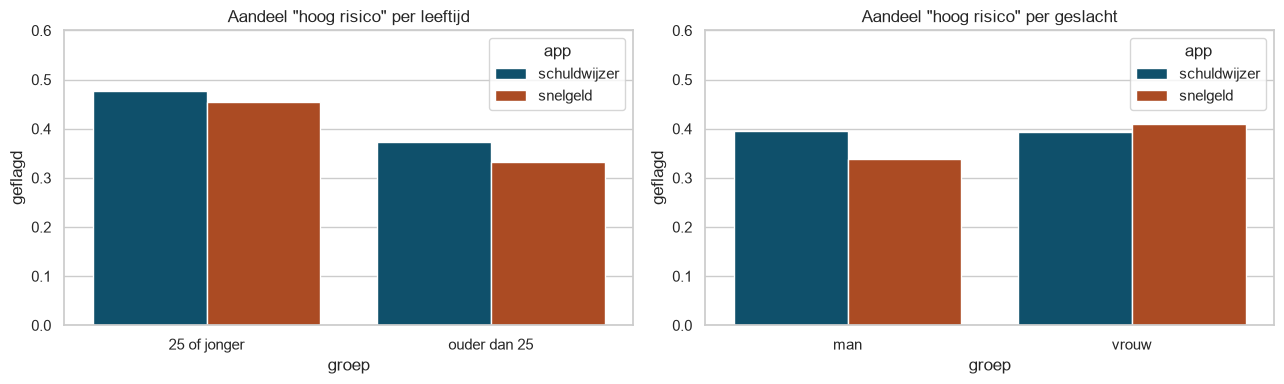

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, kenmerk in zip(axes, ['leeftijd', 'geslacht']):
    d = fair[fair.kenmerk == kenmerk]
    sns.barplot(data=d, x='groep', y='geflagd', hue='app', ax=ax, palette={'schuldwijzer': ACC, 'snelgeld': RISK})
    ax.set_title(f'Aandeel "hoog risico" per {kenmerk}'); ax.set_ylim(0, 0.6)
plt.tight_layout(); plt.show()

**Wat we zien, eerlijk benoemd:**

- **Proxy-bias.** Ook zonder leeftijd flagt Schuldwijzer jongeren vaker. Kenmerken als dienstverband, woonsituatie en spaargeld hangen samen met leeftijd. Kenmerken weglaten is dus nodig, maar niet genoeg.
- Het verschil volgt grotendeels het **echte** verschil in de data (46% tegen 26% bad), en het aandeel vals alarm (FPR) ligt voor beide groepen dicht bij elkaar. Schuldwijzer maakt bij jongeren dus niet vaker een fout. Omdat de app beschermt en niet weigert, is een waarschuwing voor een groep met echt meer risico te verdedigen.
- **SnelGeld** gebruikt geslacht en leeftijd direct. Vrouwen krijgen daar een hogere gemiddelde risicoscore (36% tegen 30%) en worden vaker als 'hoog' gezien (41% tegen 34%), terwijl Schuldwijzer mannen en vrouwen vrijwel gelijk behandelt (40% tegen 39%). SnelGeld zet die score bovendien om in een hogere rente. Dezelfde ongelijkheid wordt daar *uitgebuit* in plaats van *opgevangen*.
- **Voorbehoud:** de groepen zijn klein (bijvoorbeeld 44 jongeren en 6 "niet buitenlands" in de testset). Conclusies zijn indicatief.

## 8. Explainability: globaal en lokaal

**Globaal (permutation importance):** hoeveel slechter wordt de AUC als we één feature door elkaar husselen? Dit staat in de app onder *Hoe het werkt*.

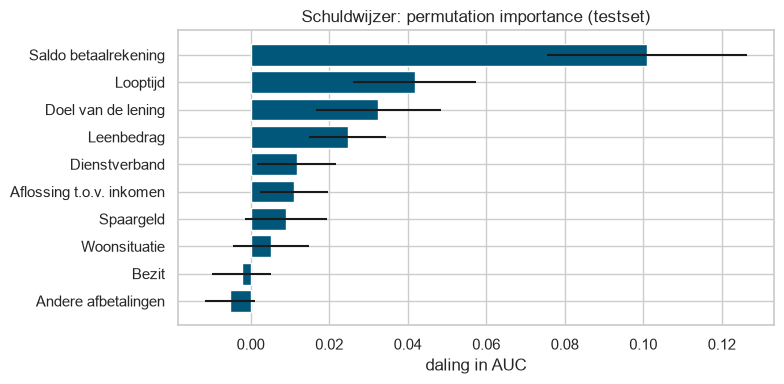

In [14]:
imp = pd.DataFrame(metrics['schuldwijzer']['importance'])
imp['label'] = imp['feature'].map(lambda f: FEATURES[f]['short'])
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp['label'][::-1], imp['mean'][::-1], xerr=imp['std'][::-1], color=ACC)
ax.set_xlabel('daling in AUC'); ax.set_title('Schuldwijzer: permutation importance (testset)')
plt.tight_layout(); plt.show()

**Lokaal (exacte Shapley-waarden):** waarom krijgt *deze* persoon *deze* uitkomst? Voor elke subset van de 10 features rekenen we de gemiddelde voorspelling uit, met de overige features uit een achtergrondsteekproef van 40 aanvragen. Met 10 features zijn dat 2^10 = 1024 subsets: klein genoeg om exact te rekenen in plaats van te benaderen (zoals SHAP's KernelExplainer). Dit kost ongeveer 30 ms per aanvraag. De bijdragen tellen precies op tot de voorspelling.

In [15]:
P = Predictor(joblib.load(ROOT / 'models' / 'schuldwijzer.joblib'))
damian = {f: DAMIAN[f] for f in SCHULDWIJZER_FEATURES}
s = P.shapley(damian)
print(f"basis (gemiddelde aanvrager): {s['base']:.3f}")
print(f"basis + som bijdragen:        {s['base'] + sum(s['phi'].values()):.3f}")
print(f"voorspelling model:           {P.proba(damian):.3f}")
ex = pd.DataFrame(P.explain(damian))[['label', 'value_label', 'contribution']]
ex

basis (gemiddelde aanvrager): 0.330
basis + som bijdragen:        0.844
voorspelling model:           0.844


,label,value_label,contribution
0,Looptijd,48 maanden,0.2125
1,Doel van de lening,Tweedehands auto,-0.1247
2,Woonsituatie,Ik huur,0.0795
3,Saldo betaalrekening,Tussen € 0 en € 100,0.0766
4,Spaargeld,Minder dan € 50,0.0612
5,Andere afbetalingen,"Ja, bij een winkel of achteraf betalen",0.0586
6,Dienstverband,Korter dan 1 jaar,0.0565
7,Bezit,Geen noemenswaardig bezit,0.0550
8,Aflossing t.o.v. inkomen,35% of meer,0.0371
9,Leenbedrag,€ 3.000,0.0019


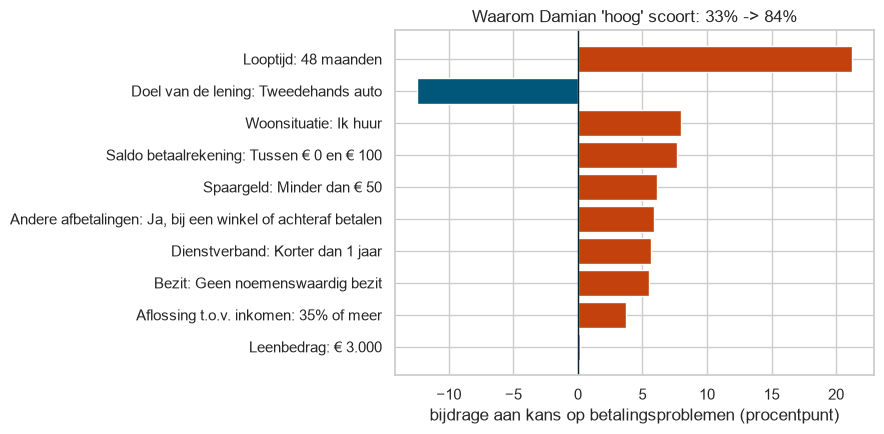

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
e = ex.iloc[::-1]
ax.barh(e['label'] + ': ' + e['value_label'], e['contribution'] * 100,
        color=[RISK if c > 0 else ACC for c in e['contribution']])
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel('bijdrage aan kans op betalingsproblemen (procentpunt)')
ax.set_title(f"Waarom Damian 'hoog' scoort: {s['base']:.0%} -> {P.proba(damian):.0%}")
plt.tight_layout(); plt.show()

## 9. Wat verlaagt het risico? (counterfactuals)

Uitleg wordt pas bruikbaar als je weet wat je kunt doen (AI-UX: *control*). Schuldwijzer zoekt daarom twee soorten alternatieven:

- **Aan de lening:** bedrag en looptijd, maar alleen opties waarbij het maandbedrag niet stijgt. Het model houdt "aflossing t.o.v. inkomen" vast, waardoor een kortere looptijd anders onterecht gratis zou lijken.
- **Aan je situatie, op termijn:** de eerstvolgende haalbare stap in spaargeld, saldo of lopende afbetalingen.

In [17]:
pd.DataFrame(P.counterfactuals(damian)), pd.DataFrame(P.levers(damian))

(   credit_amount  duration  probability  band  verschil
 0         2250.0        36       0.8013  hoog   -0.0428,
                feature                 label  \
 0       savings_status             Spaargeld   
 1  other_payment_plans   Andere afbetalingen   
 2      checking_status  Saldo betaalrekening   
 
                                      from              to  probability  band  \
 0                         Minder dan € 50  € 50 tot € 250       0.7883  hoog   
 1  Ja, bij een winkel of achteraf betalen             Nee       0.8043  hoog   
 2                     Tussen € 0 en € 100  Meer dan € 100       0.8058  hoog   
 
    verschil  
 0   -0.0558  
 1   -0.0398  
 2   -0.0383  )

Voor Damian helpt aan de lening schuiven weinig: zijn situatie (weinig buffer, kort in dienst, al een afbetaling bij een winkel) weegt zwaarder. De app zegt dat ook eerlijk, in plaats van een schijnoplossing te bieden.

## 10. SnelGeld: dezelfde voorspelling, omgezet in winst

De prijslogica staat in `backend/app/pricing.py`. Rente = basis + risico-opslag (uit het model) + haast-opslag + leeftijdsopslag + opslag op nationaliteit. Hoog risico krijgt daarnaast 50% méér geld aangeboden.

In [18]:
from backend.app.pricing import offer
S = Predictor(joblib.load(ROOT / 'models' / 'snelgeld.joblib'))
hoog = S.meta['thresholds']['hoog_vanaf']
scen = {
    'Damian (24, haast)': ({**DAMIAN}, 'vandaag'),
    'Damian zonder haast': ({**DAMIAN}, 'geen_haast'),
    'Zelfde profiel, 40 jaar': ({**DAMIAN, 'age': 40}, 'geen_haast'),
    'Zelfde profiel, buitenlandse nationaliteit': ({**DAMIAN, 'foreign_worker': 'yes'}, 'vandaag'),
    'Zelfde profiel, vrouw': ({**DAMIAN, 'personal_status': 'female div/dep/mar'}, 'vandaag'),
}
rows = []
for name, (v, u) in scen.items():
    p = S.proba(v); o = offer(v, p, u, hoog)
    rows.append({'scenario': name, 'kans bad (model)': round(p, 3), 'rente %': o['apr'],
                 'aangeboden': o['upsell_amount'], 'looptijd': o['months'],
                 'maandbedrag': o['monthly'], 'totaal terug': o['total']})
pd.DataFrame(rows)

,scenario,kans bad (model),rente %,aangeboden,looptijd,maandbedrag,totaal terug
0,"Damian (24, haast)",0.719,28.3,4500,72,86.99,6412.32
1,Damian zonder haast,0.719,24.3,4500,72,79.53,5875.00
2,"Zelfde profiel, 40 jaar",0.665,21.9,4500,72,75.20,5563.43
3,"Zelfde profiel, buitenlandse nationaliteit",0.797,29.9,4500,72,90.06,6633.26
4,"Zelfde profiel, vrouw",0.744,28.8,4500,72,87.94,6481.01


Zelfde persoon, zelfde lening: alleen door geslacht, leeftijd, nationaliteit of haast betaalt hij of zij tientallen tot honderden euro's meer (Damian met haast tegenover hetzelfde profiel op 40 jaar zonder haast: ruim 800 euro). En het model voorspelt bij Damian een hoog risico op betalingsproblemen, maar SnelGeld toont "Goedgekeurd · 98% match".

## 11. Conclusie

- Een klein, gekalibreerd **neuraal netwerk** voorspelt kredietrisico met een AUC van ongeveer 0,78 tot 0,82 op ongeziene data. Dat is vergelijkbaar met logistische regressie en ruim beter dan gokken.
- **Dataminimalisatie en het weglaten van beschermde kenmerken kosten vrijwel geen nauwkeurigheid.** Schuldwijzer vraagt 10 gegevens; SnelGeld vraagt er meer dan 20, plus naam, e-mail, telefoon en toestemming voor contacten en locatie.
- **Bias verdwijnt niet door kenmerken weg te laten** (proxy-bias). Daarom meten we het, en tonen we het eerlijk in de app.
- **Explainability** is in Schuldwijzer een recht van de gebruiker (exacte Shapley-uitleg plus alternatieven). In SnelGeld wordt dezelfde kennis verborgen en tegen de gebruiker ingezet.
- Het verschil tussen goed en kwaad zit niet in het model, maar in **wat je met de voorspelling doet**: beschermen of uitbuiten.